# Predicting Beijing PM2.5 Air Pollution from Weather with Machine Learning

**Environmental problem:** PM2.5 haze is one of the most harmful forms of air pollution. Emissions create it, but
**weather decides whether it disperses or accumulates**.

**Goal:** predict hourly PM2.5 (µg/m³) from weather + time only, compare **7 ML models**, tune the best ones,
and explain which weather factors drive pollution (SHAP).

**Research questions**
1. How accurately can meteorological conditions predict hourly PM2.5?
2. Which machine learning model performs best?
3. Which weather factors most strongly control PM2.5, and how?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/6730467221/Environmental-ML-Project/blob/main/notebooks/ML_analysis.ipynb)

## Step 1: Import Libraries

In [1]:
# (Google Colab) uncomment if a library is missing
# !pip install -q xgboost lightgbm shap

import os, time, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

In [2]:
# scikit-learn: preprocessing, models, tuning, metrics
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# Gradient boosting libraries + explainable ML
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap

In [3]:
RANDOM_STATE = 42
FIG_DIR = '../figures/' if os.path.isdir('../figures') else 'figures/'
os.makedirs(FIG_DIR, exist_ok=True)

# colour-blind-safe palette + clean chart style
BLUE, ORANGE, AQUA, YELLOW, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
DIVERGING = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#eb6834'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'axes.titleweight': 'bold'})

def save(name):
    plt.savefig(FIG_DIR + name)
    plt.show()

## Step 2: Import the Dataset

**Beijing PM2.5 Data** (UCI Machine Learning Repository / Kaggle) — hourly PM2.5 at the US Embassy in Beijing +
weather from Beijing Capital International Airport, 2010–2014.

| Column | Meaning |
|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³) — **target** |
| `DEWP` | Dew point (°C) |
| `TEMP` | Temperature (°C) |
| `PRES` | Pressure (hPa) |
| `cbwd` | Wind direction (NE, NW, SE, cv = calm/variable) |
| `Iws` | Cumulated wind speed (m/s) |
| `Is` / `Ir` | Cumulated hours of snow / rain |

In [4]:
DATA_URL = 'https://raw.githubusercontent.com/6730467221/Environmental-ML-Project/main/data/beijing_pm25.csv'
local_path = '../data/beijing_pm25.csv'

df = pd.read_csv(local_path) if os.path.exists(local_path) else pd.read_csv(DATA_URL)
df.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


## Step 3: Explore the Dataset

In [5]:
# Check dataset size
df.shape

(43824, 13)

In [6]:
# Check data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


In [7]:
# Summary statistics
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
No,43824.0,21912.5,12651.0,1.0,10956.8,21912.5,32868.2,43824.0
year,43824.0,2012.0,1.4,2010.0,2011.0,2012.0,2013.0,2014.0
month,43824.0,6.5,3.4,1.0,4.0,7.0,10.0,12.0
day,43824.0,15.7,8.8,1.0,8.0,16.0,23.0,31.0
hour,43824.0,11.5,6.9,0.0,5.8,11.5,17.2,23.0
pm2.5,41757.0,98.6,92.1,0.0,29.0,72.0,137.0,994.0
DEWP,43824.0,1.8,14.4,-40.0,-10.0,2.0,15.0,28.0
TEMP,43824.0,12.4,12.2,-19.0,2.0,14.0,23.0,42.0
PRES,43824.0,1016.4,10.3,991.0,1008.0,1016.0,1025.0,1046.0
Iws,43824.0,23.9,50.0,0.4,1.8,5.4,21.9,585.6


In [8]:
# Missing values
print(df.isna().sum())
print(f"\nPM2.5 missing: {df['pm2.5'].isna().mean():.1%}")

No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64

PM2.5 missing: 4.7%


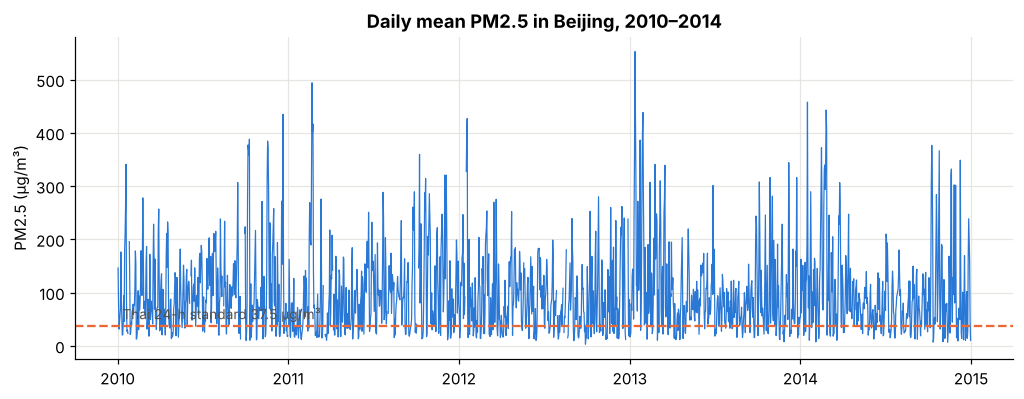

Days above Thai standard: 77%


In [9]:
# Build a datetime index
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
eda = df.set_index('datetime')

# Daily mean PM2.5 over 5 years
daily = eda['pm2.5'].resample('D').mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily, color=BLUE, lw=0.8)
ax.axhline(37.5, color=ORANGE, lw=1.5, ls='--')
ax.text(daily.index[10], 50, 'Thai 24-h standard 37.5 µg/m³', color='#52514e', fontsize=9)
ax.set_title('Daily mean PM2.5 in Beijing, 2010–2014'); ax.set_ylabel('PM2.5 (µg/m³)')
save('01_pm25_timeseries.png')
print(f"Days above Thai standard: {(daily > 37.5).mean():.0%}")

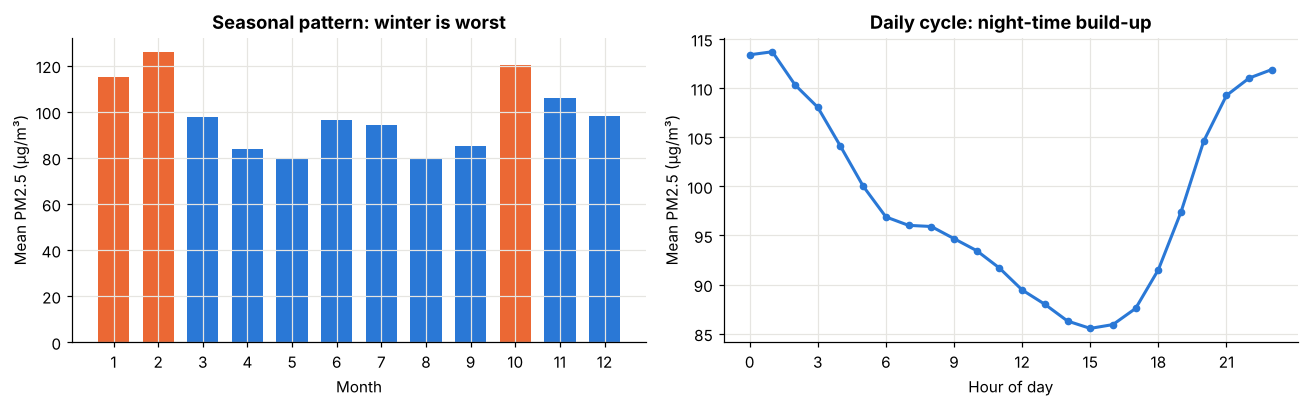

In [10]:
# Seasonal (monthly) and daily (hourly) pattern
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
m = eda.groupby('month')['pm2.5'].mean()
axes[0].bar(m.index, m.values, color=[ORANGE if v > 110 else BLUE for v in m.values], width=0.7)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel('Month'); axes[0].set_ylabel('Mean PM2.5 (µg/m³)')
axes[0].set_title('Seasonal pattern: winter is worst')
h = eda.groupby('hour')['pm2.5'].mean()
axes[1].plot(h.index, h.values, color=BLUE, lw=2, marker='o', ms=4)
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel('Hour of day'); axes[1].set_ylabel('Mean PM2.5 (µg/m³)')
axes[1].set_title('Daily cycle: night-time build-up')
plt.tight_layout()
save('02_seasonal_daily_pattern.png')

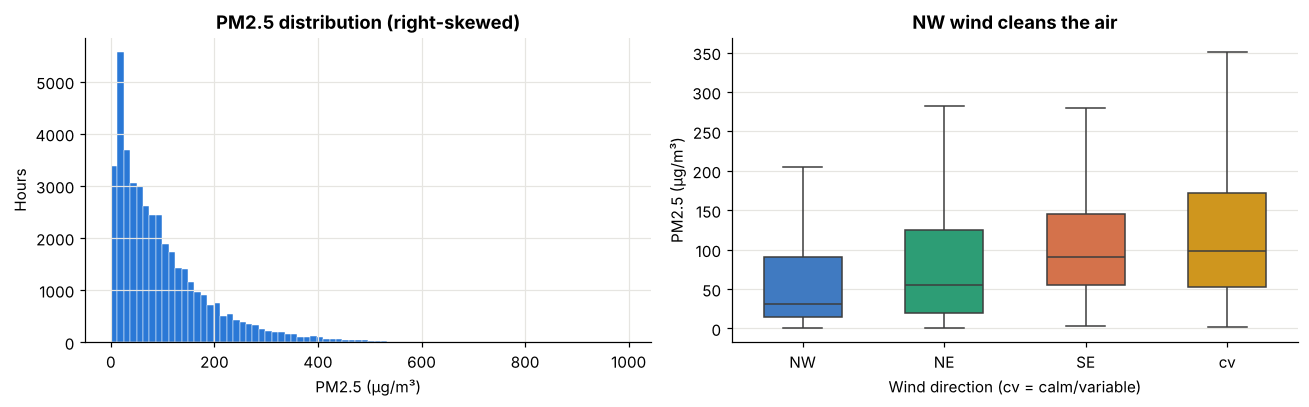

cbwd
NW     70.0
NE     90.0
SE    111.0
cv    126.0
Name: pm2.5, dtype: float64


In [11]:
# Distribution + wind direction
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(eda['pm2.5'].dropna(), bins=80, color=BLUE, edgecolor='white', linewidth=0.3)
axes[0].set_xlabel('PM2.5 (µg/m³)'); axes[0].set_ylabel('Hours'); axes[0].set_title('PM2.5 distribution (right-skewed)')
sns.boxplot(data=eda, x='cbwd', y='pm2.5', order=['NW', 'NE', 'SE', 'cv'], ax=axes[1], showfliers=False,
            palette=[BLUE, AQUA, ORANGE, YELLOW], width=0.55)
axes[1].set_xlabel('Wind direction (cv = calm/variable)'); axes[1].set_ylabel('PM2.5 (µg/m³)')
axes[1].set_title('NW wind cleans the air')
plt.tight_layout()
save('03_distribution_wind.png')
print(eda.groupby('cbwd')['pm2.5'].mean().round(0).sort_values())

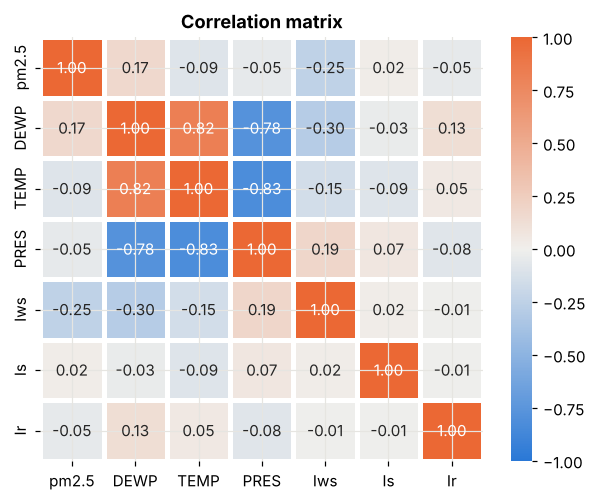

In [12]:
# Correlation matrix
num_cols = ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(eda[num_cols].corr(), annot=True, fmt='.2f', cmap=DIVERGING, vmin=-1, vmax=1, ax=ax,
            linewidths=2, linecolor='white')
ax.set_title('Correlation matrix')
save('04_correlation.png')

## Step 4: Data Preprocessing

* Sort by time (continuous hourly index)
* Rows with missing PM2.5 are **removed** (not imputed) — after rolling features are built
* One-hot encode wind direction; sin/cos encode hour and month

In [13]:
data = df.drop(columns=['No']).set_index('datetime').sort_index()
print('From', data.index.min(), 'to', data.index.max(), '| rows:', len(data))

From 2010-01-01 00:00:00 to 2014-12-31 23:00:00 | rows: 43824


## Step 5: Feature Engineering

Physically based features describing **humidity and atmospheric stagnation**:
`RH` (relative humidity, Magnus formula), `dew_spread`, rolling 24 h / 72 h means, 24 h pressure change,
`hrs_since_NW` (hours since the last clean north-westerly wind), `rain_24h`, plus cyclic time features.

In [14]:
# Relative humidity from temperature and dew point (Magnus formula)
a, b = 17.625, 243.04
data['RH'] = (100 * np.exp(a * data['DEWP'] / (b + data['DEWP']))
                  / np.exp(a * data['TEMP'] / (b + data['TEMP']))).clip(0, 100)
data['dew_spread'] = data['TEMP'] - data['DEWP']

In [15]:
# Rolling (past) weather: 24 h and 72 h means
for col in ['DEWP', 'Iws', 'PRES', 'TEMP', 'RH']:
    data[f'{col}_24h'] = data[col].rolling(24, min_periods=1).mean()
for col in ['DEWP', 'Iws']:
    data[f'{col}_72h'] = data[col].rolling(72, min_periods=1).mean()

data['PRES_chg24'] = data['PRES'].diff(24)                                   # pressure change (fronts)
data['rain_24h'] = (data['Ir'].rolling(24, min_periods=1).max() > 0).astype(int)

In [16]:
# Hours since the last north-westerly (clean) wind = how long air has been stagnant
is_nw = (data['cbwd'] == 'NW').astype(int)
data['hrs_since_NW'] = is_nw.groupby(is_nw.cumsum()).cumcount().where(is_nw == 0, 0).clip(upper=240)

In [17]:
# Cyclic time features + one-hot wind direction
data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24)
data['hour_cos'] = np.cos(2 * np.pi * data['hour'] / 24)
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)
data['dayofweek'] = data.index.dayofweek
data = pd.get_dummies(data, columns=['cbwd'], prefix='wind', dtype=int)

# Remove rows without a target
data = data.dropna(subset=['pm2.5', 'PRES_chg24'])
data.shape

(41757, 32)

In [18]:
BASE_FEATURES = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv',
                 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dayofweek']
ENGINEERED = ['RH', 'dew_spread', 'DEWP_24h', 'DEWP_72h', 'Iws_24h', 'Iws_72h', 'PRES_24h', 'PRES_chg24',
              'TEMP_24h', 'RH_24h', 'hrs_since_NW', 'rain_24h']
FEATURES = BASE_FEATURES + ENGINEERED

X = data[FEATURES]
y = data['pm2.5']
print('Features:', len(FEATURES))

Features: 27


## Step 6: Train/Test Split (time-based)

Train = 2010–2013, Test = 2014 (a year the model has never seen). A random split would leak neighbouring hours.

In [19]:
train_mask = data['year'] < 2014
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (33096, 27)
Testing: (8661, 27)


In [20]:
# Helper: evaluate a model on the test set and store results
results = {}
predictions = {}

def evaluate(name, y_pred):
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    results[name] = {'R2': r2, 'MAE': mae, 'RMSE': rmse}
    predictions[name] = y_pred
    print(name)
    print("R²:", round(r2, 3))
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))

## Step 7: Linear Regression (baseline)

In [21]:
lr_model = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])
lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['DEWP','TEMP','PRES',...,'RH_24h','hrs_since_NW','rain_24h']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [22]:
y_pred_lr = lr_model.predict(X_test)

In [23]:
evaluate('Linear Regression', y_pred_lr)

Linear Regression
R²: 0.468
MAE: 47.54
RMSE: 68.19


## Step 8: K-Nearest Neighbours (KNN)

In [24]:
knn_model = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=15, n_jobs=-1))
])
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['DEWP','TEMP','PRES',...,'RH_24h','hrs_since_NW','rain_24h']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [25]:
y_pred_knn = knn_model.predict(X_test)

In [26]:
evaluate('KNN', y_pred_knn)

KNN
R²: 0.49
MAE: 46.61
RMSE: 66.78


## Step 9: Decision Tree Regression

In [27]:
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=RANDOM_STATE
)
dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [28]:
y_pred_dt = dt_model.predict(X_test)

In [29]:
evaluate('Decision Tree', y_pred_dt)

Decision Tree
R²: 0.344
MAE: 51.46
RMSE: 75.72


## Step 10: Random Forest Regression

In [30]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    n_jobs=-1,
    random_state=RANDOM_STATE
)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [31]:
y_pred_rf = rf_model.predict(X_test)

In [32]:
evaluate('Random Forest', y_pred_rf)

Random Forest
R²: 0.534
MAE: 44.59
RMSE: 63.83


## Step 11: Histogram Gradient Boosting

In [33]:
hgb_model = HistGradientBoostingRegressor(
    random_state=RANDOM_STATE
)
hgb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [34]:
y_pred_hgb = hgb_model.predict(X_test)

In [35]:
evaluate('Hist Gradient Boosting', y_pred_hgb)

Hist Gradient Boosting
R²: 0.558
MAE: 42.09
RMSE: 62.16


## Step 12: XGBoost Regression

In [36]:
xgb_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [37]:
y_pred_xgb = xgb_model.predict(X_test)

In [38]:
evaluate('XGBoost', y_pred_xgb)

XGBoost
R²: 0.557
MAE: 42.32
RMSE: 62.28


## Step 13: LightGBM Regression

In [39]:
lgbm_model = LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)

,learning_rate,0.05
,n_estimators,400
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [40]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [41]:
evaluate('LightGBM', y_pred_lgbm)

LightGBM
R²: 0.561
MAE: 41.84
RMSE: 61.99


## Step 14: Compare the 7 Models

In [42]:
baseline_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
baseline_df.round(3)

,R2,MAE,RMSE
LightGBM,0.561,41.839,61.991
Hist Gradient Boosting,0.558,42.089,62.164
XGBoost,0.557,42.324,62.282
Random Forest,0.534,44.589,63.834
KNN,0.490,46.610,66.779
Linear Regression,0.468,47.540,68.190
Decision Tree,0.344,51.456,75.724


## Step 15: Effect of Feature Engineering

Same LightGBM model: raw weather variables only vs. raw + engineered features.

Raw features only : R² = 0.469
Raw + engineered  : R² = 0.561


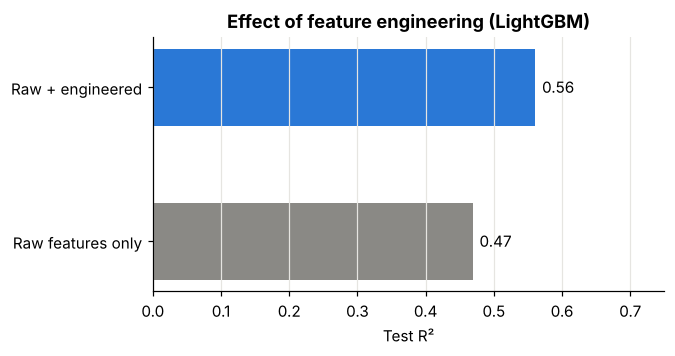

In [43]:
fe_model = LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
fe_model.fit(X_train[BASE_FEATURES], y_train)
r2_raw = r2_score(y_test, fe_model.predict(X_test[BASE_FEATURES]))
r2_eng = results['LightGBM']['R2']
print(f"Raw features only : R² = {r2_raw:.3f}")
print(f"Raw + engineered  : R² = {r2_eng:.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(['Raw features only', 'Raw + engineered'], [r2_raw, r2_eng], color=[GREY, BLUE], height=0.5)
for i, v in enumerate([r2_raw, r2_eng]):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_xlim(0, 0.75); ax.set_xlabel('Test R²'); ax.set_title('Effect of feature engineering (LightGBM)')
ax.grid(axis='y', visible=False)
save('05_feature_engineering_effect.png')

## Step 16: Hyperparameter Tuning

`RandomizedSearchCV` + `TimeSeriesSplit` (3 folds) on the training years only — the test year is never used.

In [44]:
tscv = TimeSeriesSplit(n_splits=3)

### 16.1 Tune Random Forest

In [45]:
rf_params = {
    'n_estimators': [150, 250],
    'max_depth': [12, 18, 25, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', 0.33, 0.5],
}
rf_search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
                               rf_params, n_iter=8, cv=tscv, scoring='r2', random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
print("CV R²:", round(rf_search.best_score_, 3))
evaluate('Random Forest (tuned)', rf_search.best_estimator_.predict(X_test))

Best params: {'n_estimators': 250, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
CV R²: 0.513
Random Forest (tuned)
R²: 0.551
MAE: 43.21
RMSE: 62.66


### 16.2 Tune XGBoost

In [46]:
xgb_params = {
    'n_estimators': [300, 500, 800],
    'learning_rate': [0.02, 0.03, 0.05, 0.1],
    'max_depth': [4, 6, 8],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 5, 10],
}
xgb_search = RandomizedSearchCV(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                                xgb_params, n_iter=15, cv=tscv, scoring='r2', random_state=RANDOM_STATE)
xgb_search.fit(X_train, y_train)
print("Best params:", xgb_search.best_params_)
print("CV R²:", round(xgb_search.best_score_, 3))
evaluate('XGBoost (tuned)', xgb_search.best_estimator_.predict(X_test))

Best params: {'subsample': 0.85, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
CV R²: 0.517
XGBoost (tuned)
R²: 0.567
MAE: 41.83
RMSE: 61.51


### 16.3 Tune LightGBM

In [47]:
lgbm_params = {
    'n_estimators': [300, 500, 800],
    'learning_rate': [0.02, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [10, 20, 50],
    'subsample': [0.7, 0.85, 1.0], 'subsample_freq': [1],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [0, 1, 5],
}
lgbm_search = RandomizedSearchCV(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
                                 lgbm_params, n_iter=15, cv=tscv, scoring='r2', random_state=RANDOM_STATE)
lgbm_search.fit(X_train, y_train)
print("Best params:", lgbm_search.best_params_)
print("CV R²:", round(lgbm_search.best_score_, 3))
evaluate('LightGBM (tuned)', lgbm_search.best_estimator_.predict(X_test))

Best params: {'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 1, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
CV R²: 0.533
LightGBM (tuned)
R²: 0.576
MAE: 41.28
RMSE: 60.9


## Step 17: Model Evaluation (all models)

In [48]:
all_results = pd.DataFrame(results).T.sort_values('R2', ascending=False)
all_results.to_csv(FIG_DIR + 'model_results.csv')
all_results.round(3)

,R2,MAE,RMSE
LightGBM (tuned),0.576,41.280,60.901
XGBoost (tuned),0.567,41.826,61.508
LightGBM,0.561,41.839,61.991
Hist Gradient Boosting,0.558,42.089,62.164
XGBoost,0.557,42.324,62.282
Random Forest (tuned),0.551,43.209,62.662
Random Forest,0.534,44.589,63.834
KNN,0.490,46.610,66.779
Linear Regression,0.468,47.540,68.190
Decision Tree,0.344,51.456,75.724


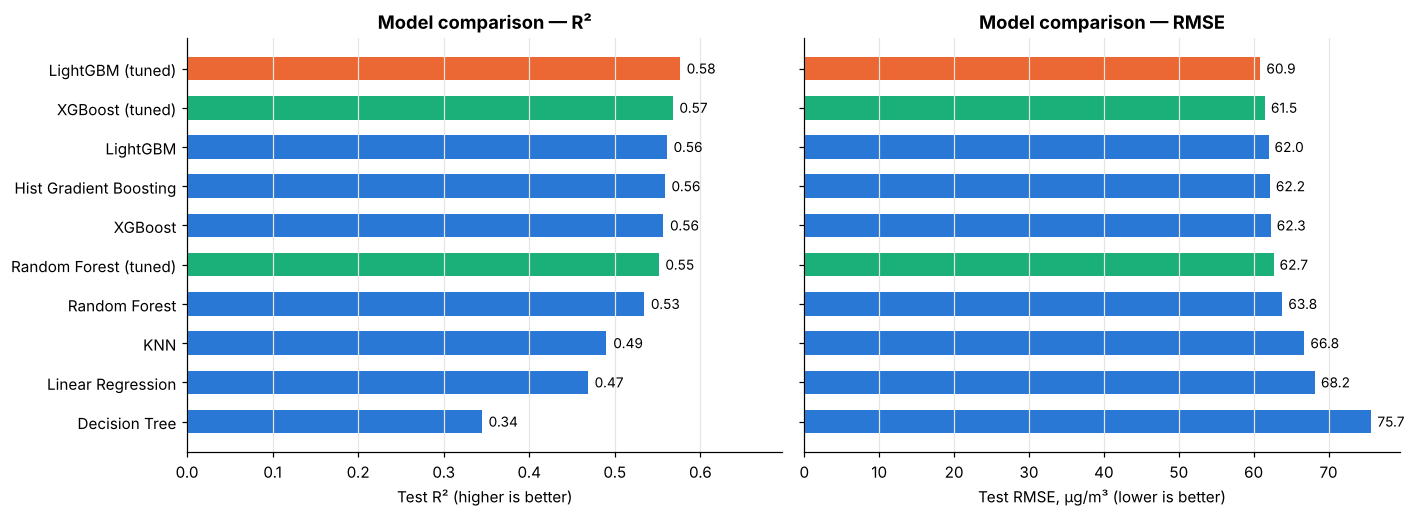

Best model: LightGBM (tuned)


In [49]:
r = all_results.sort_values('R2')
best_name = r.index[-1]
colors = [ORANGE if n == best_name else (AQUA if 'tuned' in n else BLUE) for n in r.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(r.index, r['R2'], color=colors, height=0.6)
for i, v in enumerate(r['R2']):
    axes[0].text(v + 0.008, i, f'{v:.2f}', va='center', fontsize=9)
axes[0].set_xlim(0, r['R2'].max() + 0.12); axes[0].set_xlabel('Test R² (higher is better)')
axes[0].set_title('Model comparison — R²'); axes[0].grid(axis='y', visible=False)
axes[1].barh(r.index, r['RMSE'], color=colors, height=0.6)
for i, v in enumerate(r['RMSE']):
    axes[1].text(v + 0.8, i, f'{v:.1f}', va='center', fontsize=9)
axes[1].set_xlabel('Test RMSE, µg/m³ (lower is better)'); axes[1].set_title('Model comparison — RMSE')
axes[1].set_yticklabels([]); axes[1].grid(axis='y', visible=False)
plt.tight_layout()
save('06_model_comparison.png')
print("Best model:", best_name)

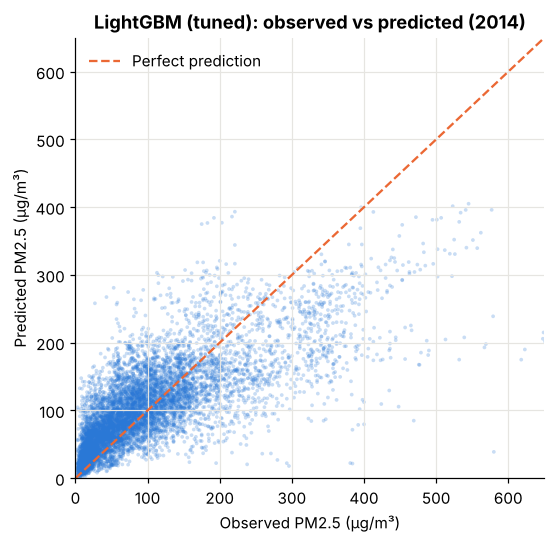

In [50]:
best_model = lgbm_search.best_estimator_
y_pred = predictions[best_name]

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(y_test, y_pred, s=6, alpha=0.25, color=BLUE, edgecolors='none')
ax.plot([0, 650], [0, 650], color=ORANGE, lw=1.5, ls='--', label='Perfect prediction')
ax.set_xlim(0, 650); ax.set_ylim(0, 650)
ax.set_xlabel('Observed PM2.5 (µg/m³)'); ax.set_ylabel('Predicted PM2.5 (µg/m³)')
ax.set_title(f'{best_name}: observed vs predicted (2014)'); ax.legend(frameon=False)
save('07_observed_vs_predicted.png')

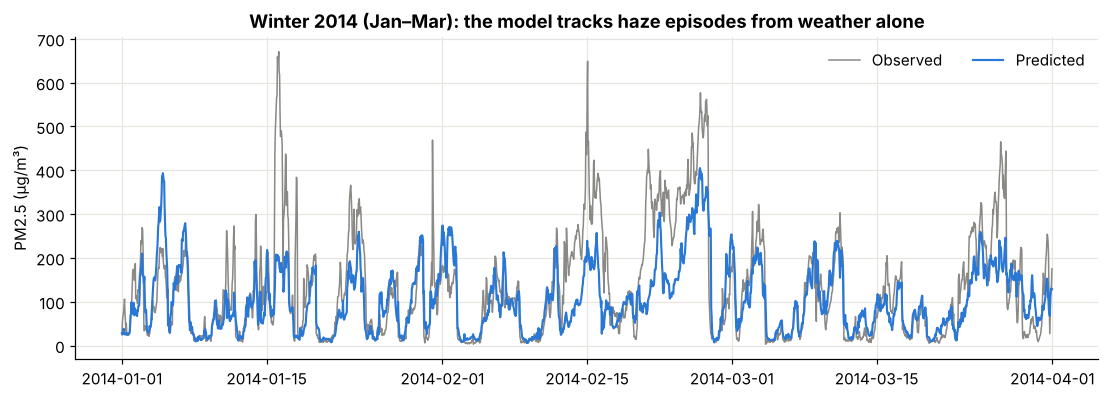

In [51]:
pred_series = pd.Series(y_pred, index=y_test.index)
obs, pred = y_test.loc['2014-01-01':'2014-03-31'], pred_series.loc['2014-01-01':'2014-03-31']
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(obs.index, obs, color=GREY, lw=1, label='Observed')
ax.plot(pred.index, pred, color=BLUE, lw=1.4, label='Predicted')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_title('Winter 2014 (Jan–Mar): the model tracks haze episodes from weather alone')
ax.legend(frameon=False, ncol=2, loc='upper right')
save('08_timeseries_prediction.png')

In [52]:
# Early warning: can the model flag unhealthy hours (PM2.5 > 75 µg/m³)?
obs_bad, pred_bad = y_test > 75, y_pred > 75
print(f"Accuracy : {(obs_bad == pred_bad).mean():.1%}")
print(f"Recall   : {(obs_bad & pred_bad).sum() / obs_bad.sum():.1%}")
print(f"Precision: {(obs_bad & pred_bad).sum() / pred_bad.sum():.1%}")

Accuracy : 79.3%
Recall   : 90.6%
Precision: 72.8%


## Step 18: Feature Importance (Explainable ML)

### 18.1 Permutation importance

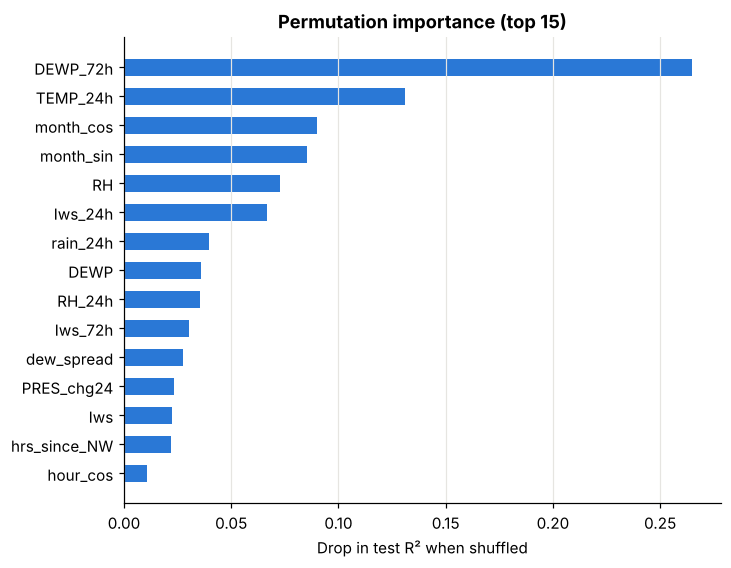

In [53]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring='r2')
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(perm_imp.index, perm_imp.values, color=BLUE, height=0.6)
ax.set_xlabel('Drop in test R² when shuffled'); ax.set_title('Permutation importance (top 15)')
ax.grid(axis='y', visible=False)
save('09_permutation_importance.png')

### 18.2 SHAP values

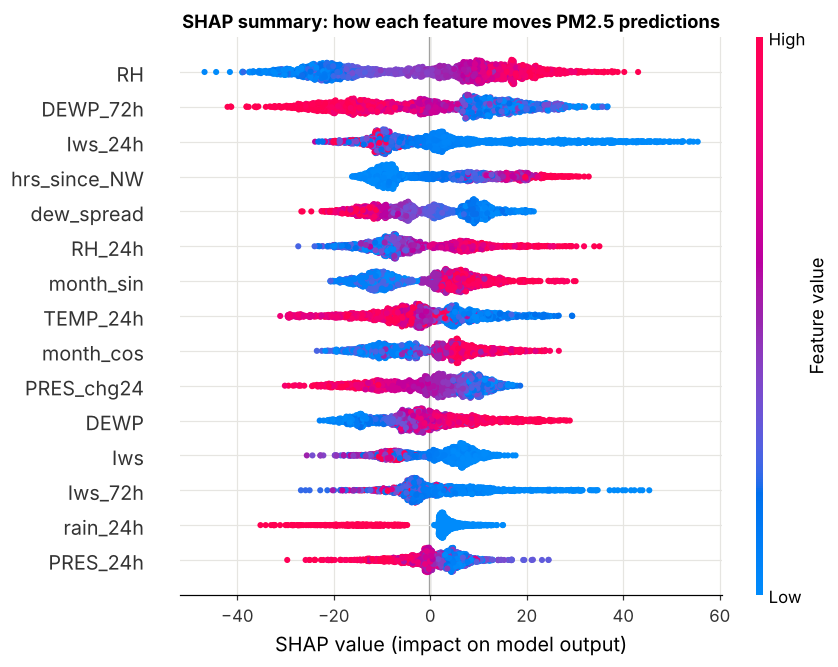

In [54]:
X_shap = X_test.sample(2000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

plt.figure()
shap.summary_plot(shap_values, X_shap, max_display=15, show=False, plot_size=(8, 6))
plt.title('SHAP summary: how each feature moves PM2.5 predictions')
save('10_shap_summary.png')

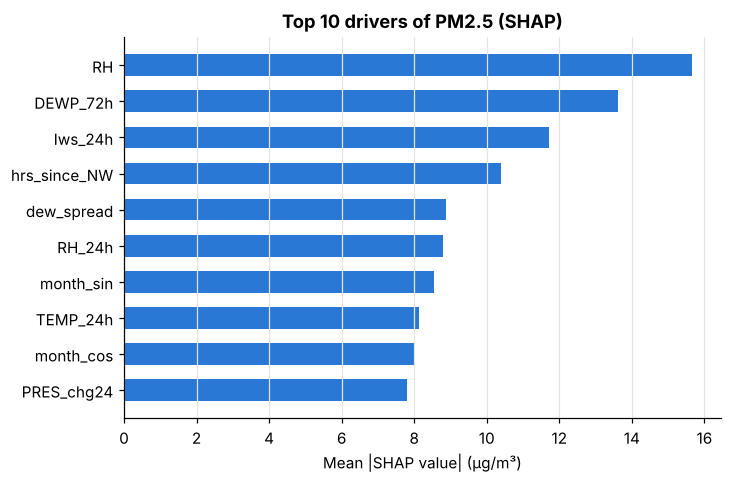

RH              15.7
DEWP_72h        13.6
Iws_24h         11.7
hrs_since_NW    10.4
dew_spread       8.9
RH_24h           8.8
month_sin        8.5
TEMP_24h         8.1
month_cos        8.0
PRES_chg24       7.8
dtype: float64

In [55]:
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(mean_abs_shap.index, mean_abs_shap.values, color=BLUE, height=0.6)
ax.set_xlabel('Mean |SHAP value| (µg/m³)'); ax.set_title('Top 10 drivers of PM2.5 (SHAP)')
ax.grid(axis='y', visible=False)
save('11_shap_top10.png')
mean_abs_shap.sort_values(ascending=False).round(1)

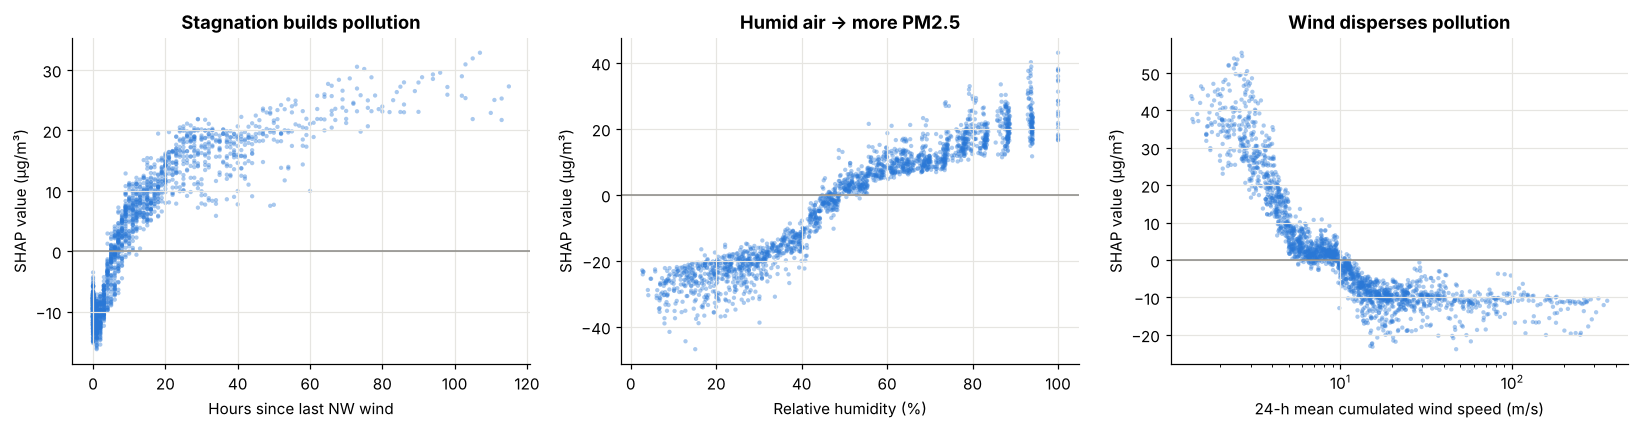

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat, label, title in zip(
        axes, ['hrs_since_NW', 'RH', 'Iws_24h'],
        ['Hours since last NW wind', 'Relative humidity (%)', '24-h mean cumulated wind speed (m/s)'],
        ['Stagnation builds pollution', 'Humid air → more PM2.5', 'Wind disperses pollution']):
    i = FEATURES.index(feat)
    ax.scatter(X_shap[feat], shap_values[:, i], s=8, alpha=0.4, color=BLUE, edgecolors='none')
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xlabel(label); ax.set_ylabel('SHAP value (µg/m³)'); ax.set_title(title)
axes[2].set_xscale('log')
plt.tight_layout()
save('12_shap_dependence.png')

## Step 19: Environmental Interpretation

1. **Weather alone explains ~58% of hourly PM2.5 variation** in an unseen year (tuned LightGBM: R² = 0.58,
   RMSE ≈ 61 µg/m³). Boosting ensembles beat linear regression, KNN and a single tree because the
   weather–pollution relationship is **non-linear** with interactions (calm + humid + winter).
   Feature engineering gave the largest gain (R² 0.47 → 0.56).
2. **Humidity is the #1 driver** — moist air promotes secondary aerosol formation (sulfate, nitrate) and particle growth.
3. **Stagnation builds pollution** — the longer since the last NW wind and the weaker the 24 h wind, the higher PM2.5.
4. **Natural cleaning:** rain (wet deposition) and rising pressure (cold fronts) lower PM2.5.
5. **Wind direction:** NW ≈ 70 µg/m³ vs SE ≈ 111 and calm ≈ 126 µg/m³.
6. **Early warning:** the model catches ~91% of unhealthy hours (> 75 µg/m³), so weather forecasts + this model
   could trigger health advisories or emission controls *before* a haze episode — also applicable to Thai cities.

**Limitations:** no emission/fire data, single station, no past PM2.5 as input.